# 🌍💨 Air Quality Index (AQI) Regression ML Project 

In [2]:
import numpy as np 
import pandas as pd
import os
import joblib
pd.set_option('display.max_columns', None)
import seaborn as sn
import matplotlib.pyplot as mp
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score
import warnings as w

w.filterwarnings('ignore')

In [3]:
# Read the data from the data/ directory
df=pd.read_csv('../data/delhiaqi.csv')

# 🧹🔍 Data Exploration and Preprocessing

In [4]:
df.drop('date',axis=1,inplace=True)

# 🌍✨ Feature Engineering

In [5]:
# Non-leaky features
df['nox'] = df['no'] + df['no2']
df['co_no_interaction'] = df['co'] * df['no']
df['so2_o3_interaction'] = df['so2'] * df['o3']
df['co_squared'] = df['co'] ** 2
df['high_co'] = np.where(df['co'] > 2000, 1, 0)

# 🧪🤖 Scaling and Dimensionality Reduction

In [6]:
x = df.drop('pm2_5', axis=1)
y = df['pm2_5']

print("Features used for training:")
print(x.columns)

Features used for training:
Index(['co', 'no', 'no2', 'o3', 'so2', 'pm10', 'nh3', 'nox',
       'co_no_interaction', 'so2_o3_interaction', 'co_squared', 'high_co'],
      dtype='object')


In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(x)

In [8]:
# Adjust PCA components since we have fewer features (12 features in `x`)
pca = PCA(n_components=10)
X_pca = pca.fit_transform(X_scaled)

# Save the corrected scaler and pca objects to the models/ directory
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(pca, '../models/pca.pkl')

['../models/pca.pkl']

In [9]:
pca_df = pd.DataFrame(data=X_pca, columns=[f'PC{i+1}' for i in range(10)])

# 🏋️‍♂️🤖 Model Training and Evaluation

In [10]:
X_train, X_test, y_train, y_test = train_test_split(pca_df, y, test_size=0.2, random_state=42)

In [11]:
stacked_model = StackingRegressor(
    estimators=[('catboost', CatBoostRegressor(verbose=0, random_seed=42)), ('lgbm', LGBMRegressor(random_state=42))],
    final_estimator=Ridge(),
    cv=3, 
    n_jobs=-1
)
stacked_model.fit(X_train, y_train)

# Save the corrected and trained stacked model to the models/ directory
joblib.dump(stacked_model, '../models/stacked_regressor_model.pkl')

['../models/stacked_regressor_model.pkl']

In [12]:
y_pred = stacked_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f'R² Score (Corrected Model): {r2:.4f}')

R² Score (Corrected Model): 0.9718


# 📊🔍 Visualizing Final Results

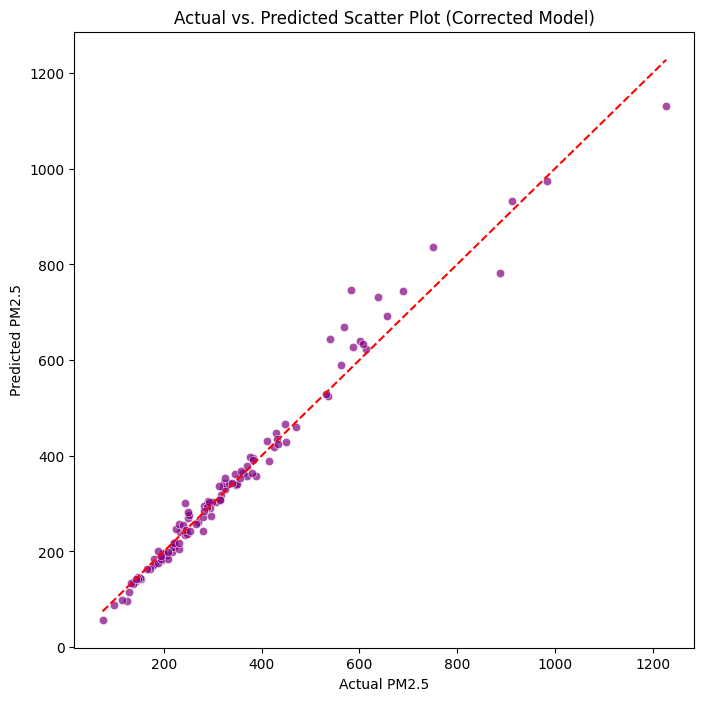

In [13]:
mp.figure(figsize=(8, 8))
sn.scatterplot(x=y_test, y=y_pred, alpha=0.7, color='purple')
mp.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='r', linestyle='--')
mp.title('Actual vs. Predicted Scatter Plot (Corrected Model)')
mp.xlabel('Actual PM2.5')
mp.ylabel('Predicted PM2.5')
mp.savefig('../outputs/graphs/corrected_actual_vs_predicted_scatter.png')
mp.show()